=== Average Results across All Folds for Rounds 1, 25, 50 (Mean ± Std) ===

DE
Round  1 | Local: RMSE 0.7999 ± 0.0441 | MAE 0.5765 ± 0.0270 | R² 0.3134 ± 0.0724 | Global: RMSE 0.9968 ± 0.0365 | MAE 0.8261 ± 0.0267 | R² -0.0594 ± 0.0391 | Time  54.20 ±  4.93s | Mem 22.14 ± 66.13MB
Round 25 | Local: RMSE 0.7686 ± 0.0602 | MAE 0.5495 ± 0.0533 | R² -0.0471 ± 1.1952 | Global: RMSE 0.8067 ± 0.0527 | MAE 0.6197 ± 0.0346 | R² 0.0511 ± 0.6475 | Time  55.44 ±  5.90s | Mem  0.20 ±  0.28MB
Round 50 | Local: RMSE 0.7242 ± 0.0577 | MAE 0.5331 ± 0.0401 | R² 0.2492 ± 0.1349 | Global: RMSE 0.7686 ± 0.0599 | MAE 0.5978 ± 0.0404 | R² 0.1257 ± 0.2170 | Time  54.36 ±  4.45s | Mem  0.08 ±  0.16MB

PSO
Round  1 | Local: RMSE 0.7955 ± 0.0601 | MAE 0.5674 ± 0.0282 | R² 0.3197 ± 0.0792 | Global: RMSE 0.9972 ± 0.0416 | MAE 0.8231 ± 0.0269 | R² -0.0566 ± 0.0351 | Time  54.27 ±  5.31s | Mem  0.03 ±  0.04MB
Round 25 | Local: RMSE 0.7675 ± 0.0672 | MAE 0.5484 ± 0.0591 | R² 0.0705 ± 0.8519 | Global: RMSE 0.8087 ± 0.0

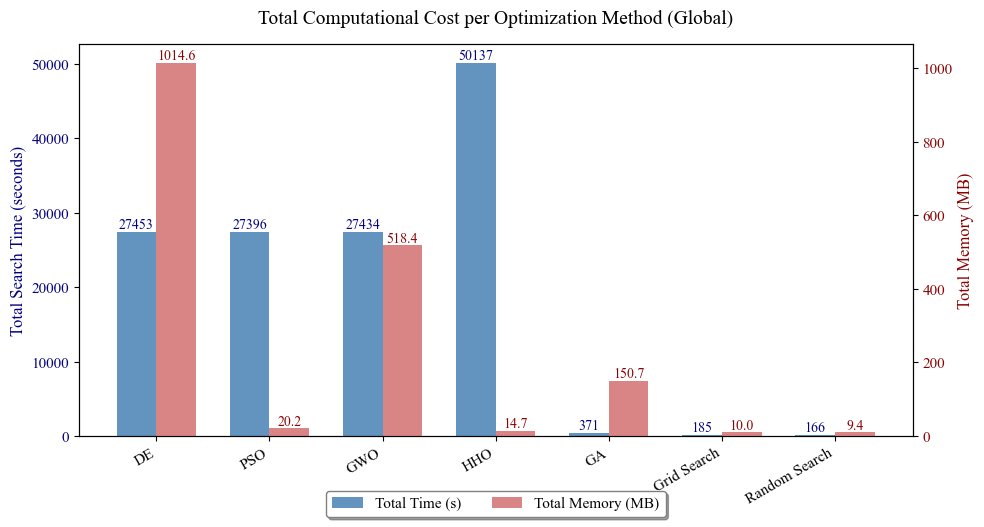

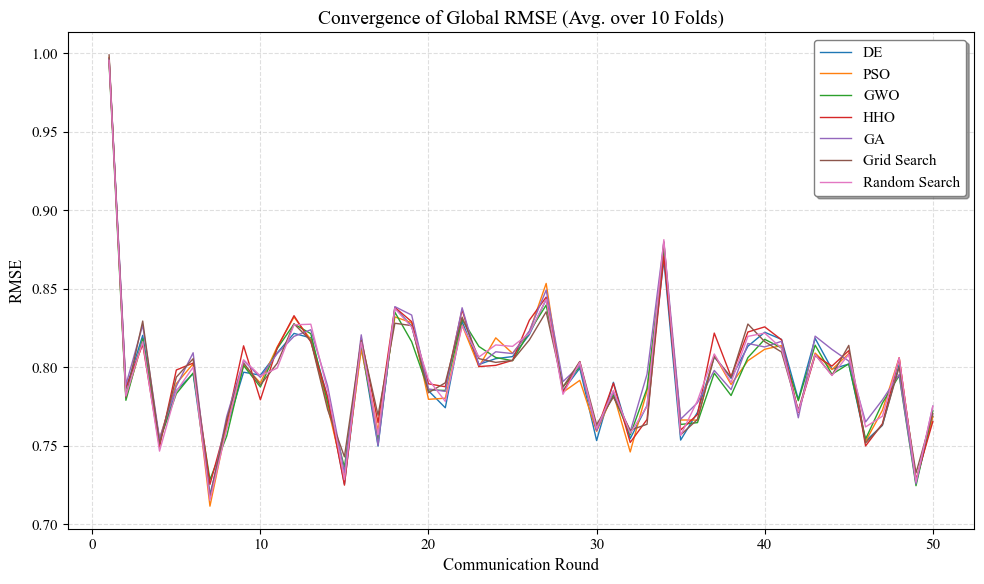

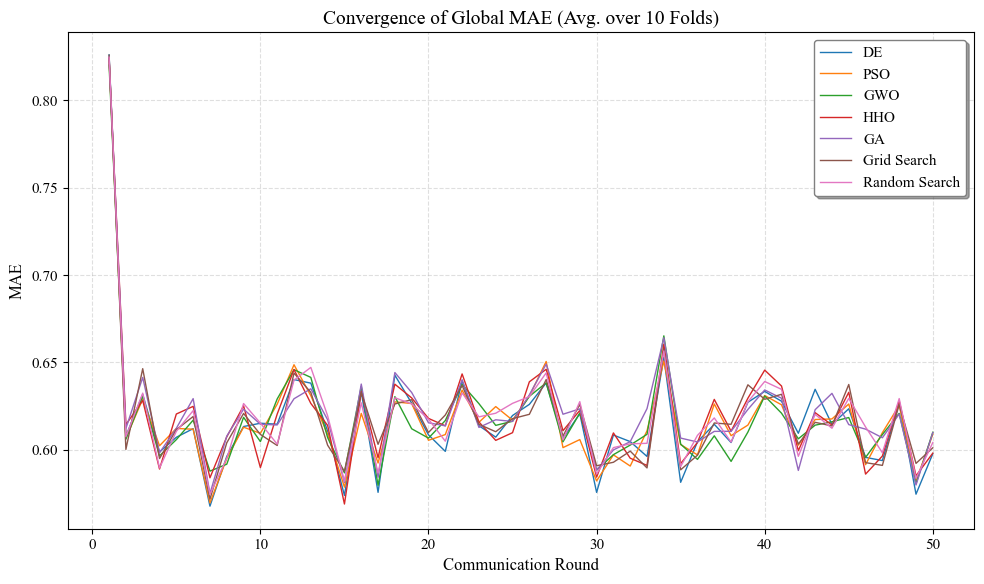

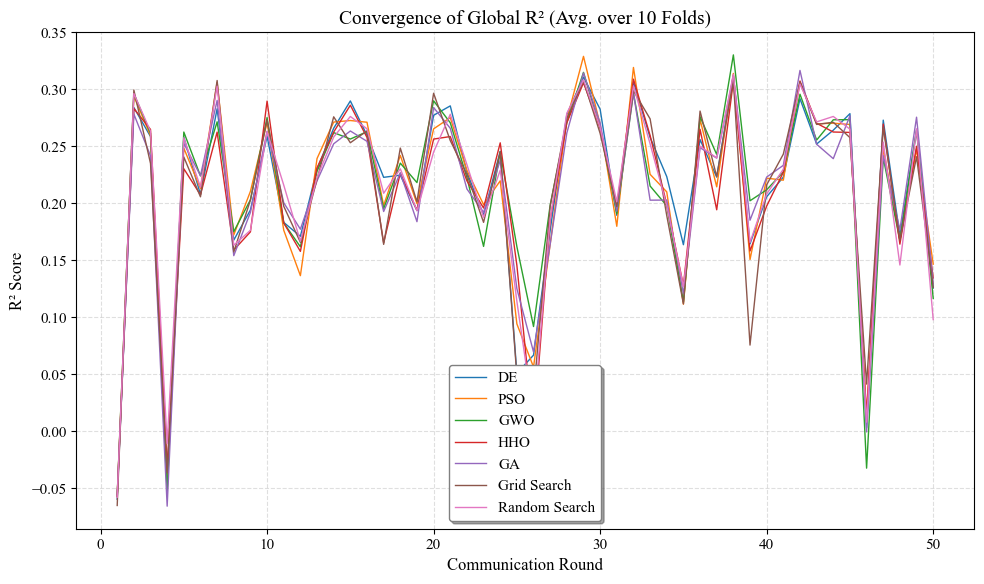

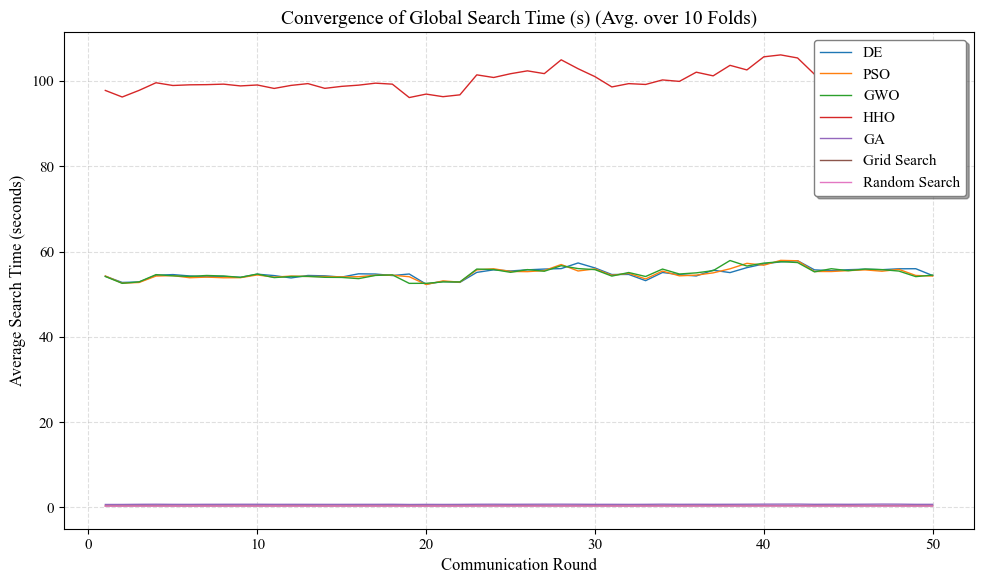

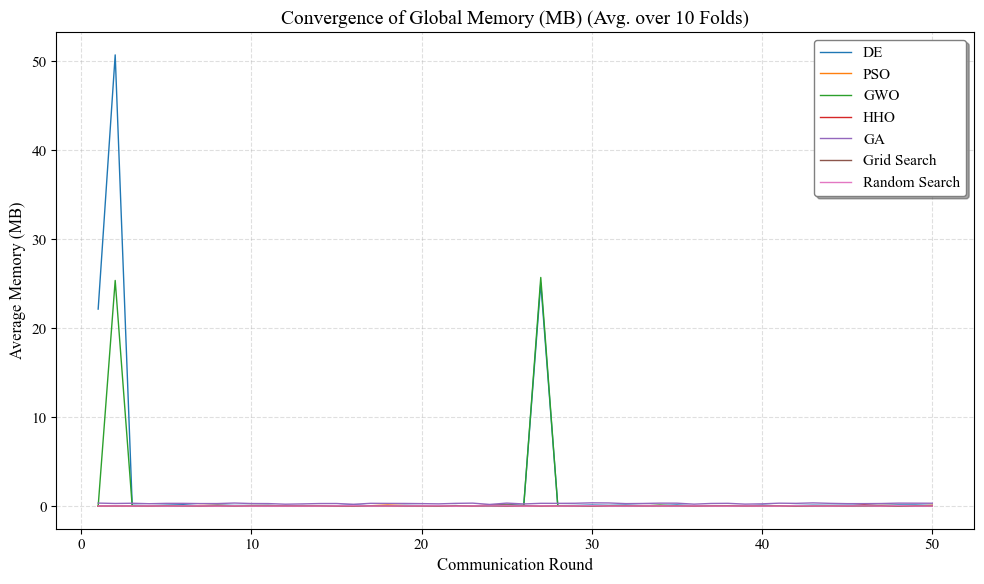


=== Global vs Local Performance Comparison (Mean ± Std, 500 values) ===
Metric | Method          | Local Mean ± Std       | Global Mean ± Std
------------------------------------------------------------------------------------------

RMSE
      DE              | 0.7547 ± 0.0951   | 0.7954 ± 0.0939
      PSO             | 0.7535 ± 0.0929   | 0.7957 ± 0.0931
      GWO             | 0.7538 ± 0.0917   | 0.7956 ± 0.0918
      HHO             | 0.7567 ± 0.0940   | 0.7976 ± 0.0930
      GA              | 0.7544 ± 0.0948   | 0.7989 ± 0.0933
      Grid Search     | 0.7554 ± 0.0962   | 0.7966 ± 0.0936
      Random Search   | 0.7557 ± 0.0939   | 0.7970 ± 0.0932

MAE
      DE              | 0.5474 ± 0.0575   | 0.6163 ± 0.0611
      PSO             | 0.5469 ± 0.0554   | 0.6169 ± 0.0596
      GWO             | 0.5466 ± 0.0548   | 0.6171 ± 0.0598
      HHO             | 0.5498 ± 0.0571   | 0.6191 ± 0.0601
      GA              | 0.5478 ± 0.0573   | 0.6208 ± 0.0603
      Grid Search     | 0.5483 ± 0.

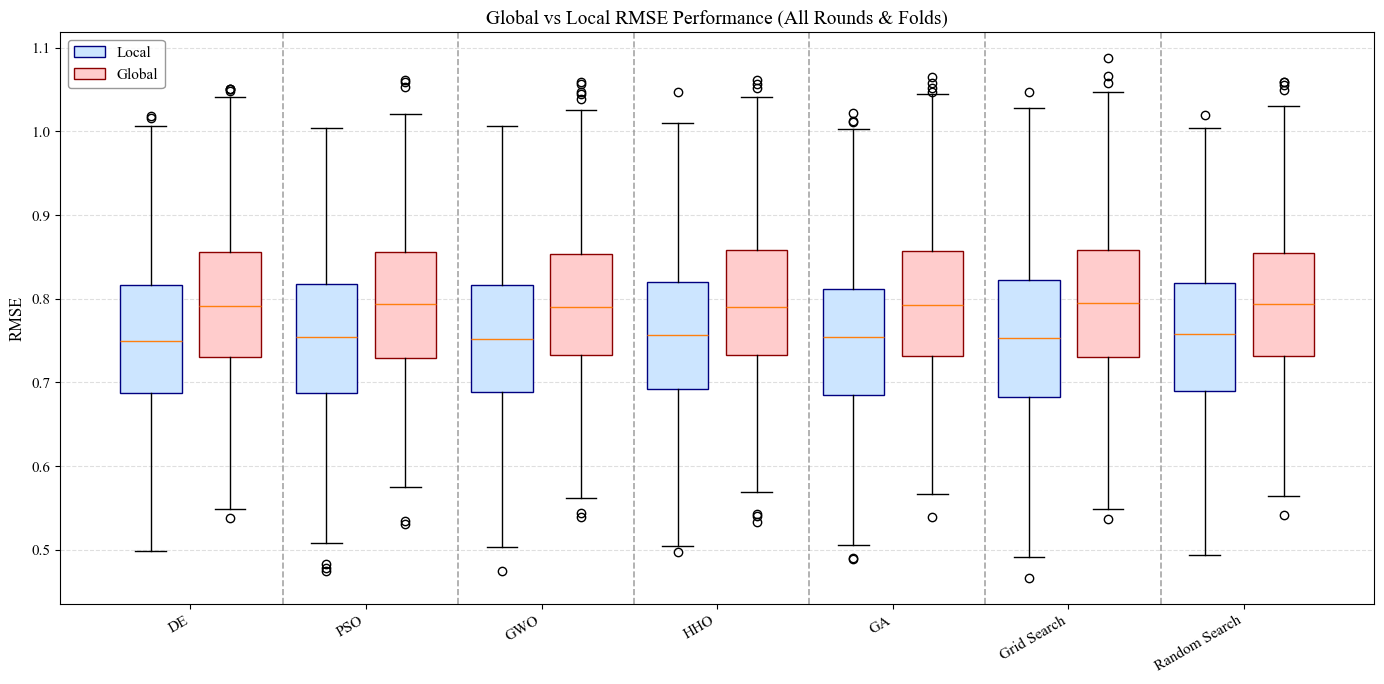

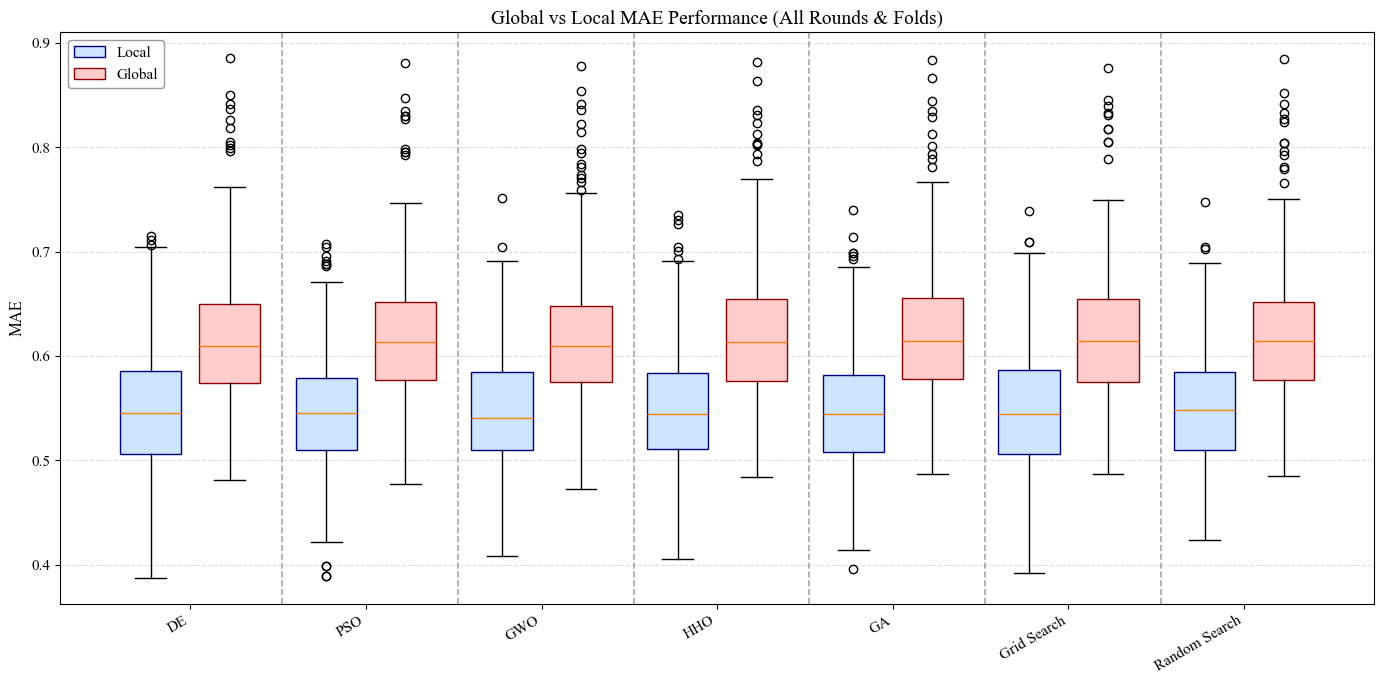

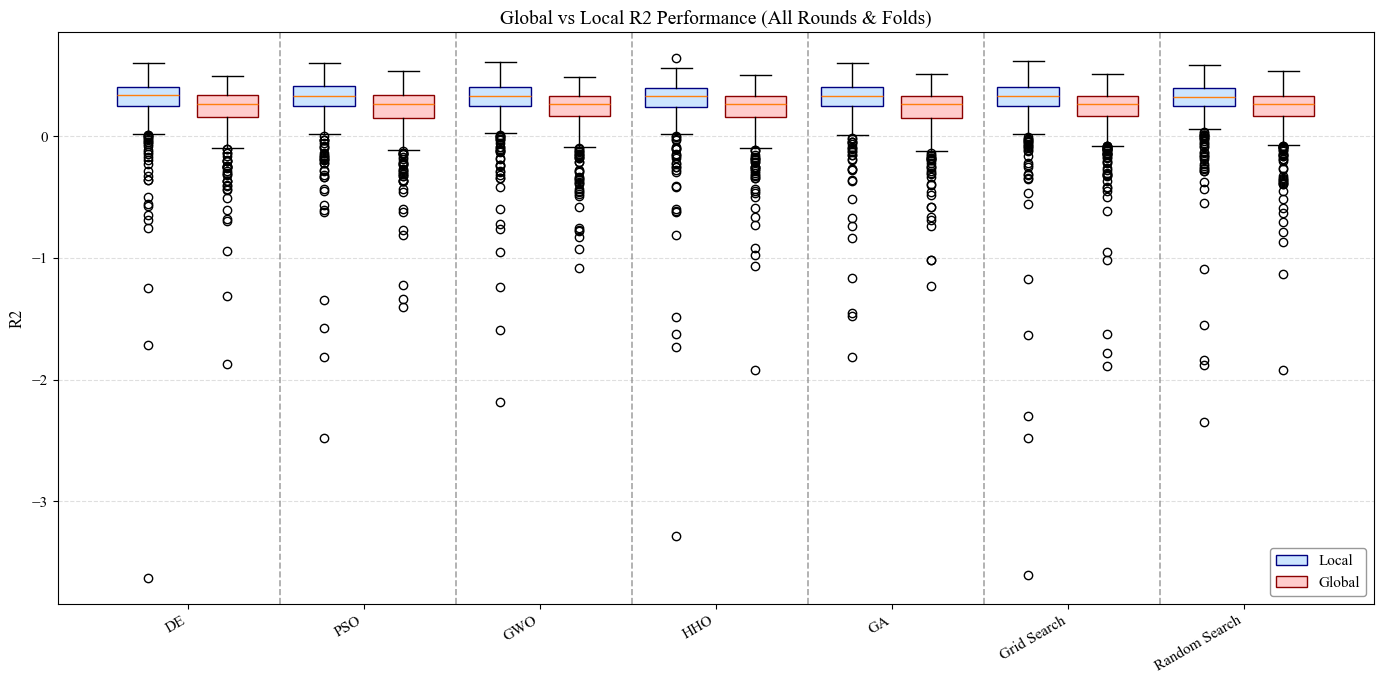

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Set tema akademik
rcParams['figure.figsize'] = (10, 6)
rcParams['font.family'] = 'serif'
rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']
rcParams['font.size'] = 12
rcParams['axes.titlesize'] = 14
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 11
rcParams['ytick.labelsize'] = 11
rcParams['legend.fontsize'] = 11
rcParams['legend.frameon'] = True
rcParams['legend.edgecolor'] = 'gray'
rcParams['legend.facecolor'] = 'white'
rcParams['legend.loc'] = 'best'
rcParams['grid.alpha'] = 0.3
rcParams['grid.linestyle'] = '--'

# Warna profesional (muted & kontras)
colors = {
    'DE': '#1f77b4',
    'PSO': '#ff7f0e',
    'GWO': '#2ca02c',
    'HHO': '#d62728',
    'GA': '#9467bd',
    'Grid Search': '#8c564b',
    'Random Search': '#e377c2'
}

# Load data
with open('fedprox_results.json', 'r') as f:
    raw_results = json.load(f)

# Restructure data (fold_* di level atas)
results = {}
for key, value in raw_results.items():
    if key.startswith('fold_'):
        fold_id = key
        for method, metrics in value.items():
            if method not in results:
                results[method] = {}
            results[method][fold_id] = metrics

methods = list(results.keys())

# 1. Print Fold 1 - Rounds 1, 25, 50 (representative)
# Ganti bagian print Fold 1 menjadi rata-rata semua fold + std
print("=== Average Results across All Folds for Rounds 1, 25, 50 (Mean ± Std) ===")

for method in methods:
    print(f"\n{method}")
    for round_num in [1, 25, 50]:
        idx = round_num - 1
        
        local_rmse_vals = []
        local_mae_vals  = []
        local_r2_vals   = []
        glob_rmse_vals  = []
        glob_mae_vals   = []
        glob_r2_vals    = []
        glob_time_vals  = []
        glob_mem_vals   = []
        
        # Kumpulkan nilai dari semua fold yang ada
        for fold_key in [k for k in results[method] if k.startswith('fold_')]:
            try:
                local_rmse_vals.append(results[method][fold_key]['local_rmse'][idx])
                local_mae_vals.append( results[method][fold_key]['local_mae'][idx])
                local_r2_vals.append(  results[method][fold_key]['local_r2'][idx])
                glob_rmse_vals.append( results[method][fold_key]['global_rmse'][idx])
                glob_mae_vals.append(  results[method][fold_key]['global_mae'][idx])
                glob_r2_vals.append(   results[method][fold_key]['global_r2'][idx])
                glob_time_vals.append( results[method][fold_key]['global_search_time'][idx])
                glob_mem_vals.append(  results[method][fold_key]['global_total_memory'][idx])
            except (KeyError, IndexError):
                continue
        
        if not glob_rmse_vals:
            print(f"Round {round_num:2d} | (Data missing for all folds)")
            continue
        
        # Hitung mean & std
        def mean_std(lst):
            if not lst:
                return np.nan, np.nan
            return np.mean(lst), np.std(lst)
        
        l_rmse_m, l_rmse_s = mean_std(local_rmse_vals)
        l_mae_m,  l_mae_s  = mean_std(local_mae_vals)
        l_r2_m,   l_r2_s   = mean_std(local_r2_vals)
        g_rmse_m, g_rmse_s = mean_std(glob_rmse_vals)
        g_mae_m,  g_mae_s  = mean_std(glob_mae_vals)
        g_r2_m,   g_r2_s   = mean_std(glob_r2_vals)
        g_time_m, g_time_s = mean_std(glob_time_vals)
        g_mem_m,  g_mem_s  = mean_std(glob_mem_vals)
        
        print(f"Round {round_num:2d} | "
              f"Local: RMSE {l_rmse_m:.4f} ± {l_rmse_s:.4f} | MAE {l_mae_m:.4f} ± {l_mae_s:.4f} | R² {l_r2_m:.4f} ± {l_r2_s:.4f} | "
              f"Global: RMSE {g_rmse_m:.4f} ± {g_rmse_s:.4f} | MAE {g_mae_m:.4f} ± {g_mae_s:.4f} | R² {g_r2_m:.4f} ± {g_r2_s:.4f} | "
              f"Time {g_time_m:6.2f} ± {g_time_s:5.2f}s | Mem {g_mem_m:5.2f} ± {g_mem_s:5.2f}MB")

# 2. Total time & memory across all folds & rounds
print("\n=== Total Search Time & Memory per Method (500 evaluations) ===")
total_data = {}
for method in methods:
    total_time = 0.0
    total_mem = 0.0
    for fold_key in [k for k in results[method] if k.startswith('fold_')]:
        total_time += sum(results[method][fold_key].get('global_search_time', []))
        total_mem += sum(results[method][fold_key].get('global_total_memory', []))
    total_data[method] = {'time': total_time, 'memory': total_mem}
    print(f"{method:>12} : Time = {total_time:10.2f} s    Memory = {total_mem:8.2f} MB")

# Bar plot dengan tema akademik
fig, ax1 = plt.subplots()
x = np.arange(len(methods))
width = 0.35

bars_time = ax1.bar(x - width/2, [total_data[m]['time'] for m in methods],
                    width, color='steelblue', alpha=0.85, label='Total Time (s)')
ax1.set_ylabel('Total Search Time (seconds)', color='navy')
ax1.tick_params(axis='y', labelcolor='navy')

ax2 = ax1.twinx()
bars_mem = ax2.bar(x + width/2, [total_data[m]['memory'] for m in methods],
                   width, color='indianred', alpha=0.75, label='Total Memory (MB)')
ax2.set_ylabel('Total Memory (MB)', color='darkred')
ax2.tick_params(axis='y', labelcolor='darkred')

ax1.set_xticks(x)
ax1.set_xticklabels(methods, rotation=30, ha='right')
ax1.set_title('Total Computational Cost per Optimization Method (Global)', pad=15, fontsize=14)

# Tambah nilai di atas bar
for bar in bars_time:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height + 50,
             f'{height:.0f}', ha='center', va='bottom', fontsize=10, color='navy')
for bar in bars_mem:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, height + 0.5,
             f'{height:.1f}', ha='center', va='bottom', fontsize=10, color='darkred')

# Legenda di dalam figure
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, -0.12),
           ncol=2, fancybox=True, shadow=True)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# 3. Line plots global metrics (average over 10 folds)
rounds = np.arange(1, 51)
metrics = ['rmse', 'mae', 'r2', 'search_time', 'total_memory']
metric_names = ['RMSE', 'MAE', 'R²', 'Search Time (s)', 'Memory (MB)']
ylabels = ['RMSE', 'MAE', 'R² Score', 'Average Search Time (seconds)', 'Average Memory (MB)']

for i, met in enumerate(metrics):
    fig, ax = plt.subplots()
    for method in methods:
        values = []
        for r in range(50):
            fold_vals = []
            for fold_key in [k for k in results[method] if k.startswith('fold_')]:
                try:
                    fold_vals.append(results[method][fold_key][f'global_{met}'][r])
                except (KeyError, IndexError):
                    continue
            if fold_vals:
                values.append(np.mean(fold_vals))
            else:
                values.append(np.nan)
        ax.plot(rounds, values, linewidth=1.0, marker='', label=method, color=colors.get(method, 'gray'))
    
    ax.set_title(f'Convergence of Global {metric_names[i]} (Avg. over 10 Folds)', fontsize=14)
    ax.set_xlabel('Communication Round', fontsize=12)
    ax.set_ylabel(ylabels[i], fontsize=12)
    ax.grid(True, which='both', linestyle='--', linewidth=0.8, alpha=0.4)
    ax.legend(loc='best', frameon=True, edgecolor='gray', facecolor='white', shadow=True)
    plt.tight_layout()
    plt.show()

# 4. Boxplot Global vs Local dengan garis pemisah
print("\n=== Global vs Local Performance Comparison (Mean ± Std, 500 values) ===")
print("Metric | Method          | Local Mean ± Std       | Global Mean ± Std")
print("-" * 90)

for met in ['rmse', 'mae', 'r2']:
    print(f"\n{met.upper()}")
    for method in methods:
        local_vals = []
        global_vals = []
        for fold_key in [k for k in results[method] if k.startswith('fold_')]:
            local_vals.extend(results[method][fold_key].get(f'local_{met}', []))
            global_vals.extend(results[method][fold_key].get(f'global_{met}', []))

        if local_vals and global_vals:
            local_mean = np.mean(local_vals)
            local_std  = np.std(local_vals)
            glob_mean  = np.mean(global_vals)
            glob_std   = np.std(global_vals)

            print(f"      {method:<15} | "
                  f"{local_mean:.4f} ± {local_std:.4f}   | "
                  f"{glob_mean:.4f} ± {glob_std:.4f}")
        else:
            print(f"      {method:<15} | (data missing)")

print("\n=== Global vs Local Performance Statistics (All Rounds & All Folds) ===")
print(" (aggregated over 10 folds × 50 rounds = up to 500 values per setting)\n")

for met in ['rmse', 'mae', 'r2']:
    print(f"\n{met.upper():^80}")
    print("-" * 95)
    print(f"{'Method':<12} | {'Type':<7} | {'count':>6} | {'mean':>9} | {'std':>9} | {'min':>9} | {'25%':>9} | {'50%':>9} | {'75%':>9} | {'max':>9}")
    print("-" * 95)
    
    for method in methods:
        local_vals = []
        global_vals = []
        
        for fold_key in [k for k in results[method] if k.startswith('fold_')]:
            local_vals.extend(results[method][fold_key].get(f'local_{met}', []))
            global_vals.extend(results[method][fold_key].get(f'global_{met}', []))
        
        for name, vals in [('Local', local_vals), ('Global', global_vals)]:
            if not vals:
                print(f" {method:<12} | {name:<7} | (no data)")
                continue
                
            s = pd.Series(vals)
            desc = s.describe()
            
            print(f" {method:<12} | {name:<7} | "
                  f"{int(desc['count']):>6d} | "
                  f"{desc['mean']:>9.4f} | "
                  f"{desc['std']:>9.4f} | "
                  f"{desc['min']:>9.4f} | "
                  f"{desc['25%']:>9.4f} | "
                  f"{desc['50%']:>9.4f} | "
                  f"{desc['75%']:>9.4f} | "
                  f"{desc['max']:>9.4f}")
    
    print("-" * 95)

print("\n=== Boxplot Comparison: Global vs Local per Method ===")
for met in ['rmse', 'mae', 'r2']:
    fig, ax = plt.subplots(figsize=(14, 7))
    positions = np.arange(len(methods)) * 4.0
    width = 1.4

    boxes = []
    labels = []

    for i, method in enumerate(methods):
        local_vals = []
        global_vals = []
        for fold_key in [k for k in results[method] if k.startswith('fold_')]:
            local_vals.extend(results[method][fold_key].get(f'local_{met}', []))
            global_vals.extend(results[method][fold_key].get(f'global_{met}', []))

        bp1 = ax.boxplot(local_vals, positions=[positions[i]], widths=width,
                         patch_artist=True, boxprops=dict(facecolor='#cce5ff', color='navy'))
        bp2 = ax.boxplot(global_vals, positions=[positions[i] + 1.8], widths=width,
                         patch_artist=True, boxprops=dict(facecolor='#ffcccc', color='darkred'))

        boxes.extend([bp1['boxes'][0], bp2['boxes'][0]])
        labels.extend(['Local', 'Global'])

        # Garis pemisah vertikal setelah setiap metode
        if i < len(methods) - 1:
            ax.axvline(x=positions[i] + 3.0, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)

    ax.set_xticks(positions + 0.9)
    ax.set_xticklabels(methods, rotation=30, ha='right')
    ax.set_title(f'Global vs Local {met.upper()} Performance (All Rounds & Folds)')
    ax.set_ylabel(met.upper())

    # Legenda sederhana: hanya Local (biru) dan Global (merah)
    ax.legend([bp1['boxes'][0], bp2['boxes'][0]], ['Local', 'Global'],
              loc='best', frameon=True, edgecolor='gray', facecolor='white')

    ax.grid(True, axis='y', linestyle='--', linewidth=0.8, alpha=0.4)
    plt.tight_layout()
    plt.show()

=== Statistical Comparison of Global Methods at Round 50 (10 folds) ===


--- RMSE (lower is better) ---
Friedman chi-square = 6.1714 | p-value = 0.404263

No significant differences (Friedman p ≥ 0.05) → performing pairwise Wilcoxon signed-rank tests
Pairwise Wilcoxon signed-rank test p-values (no correction):
------------------------------------------------------------
DE vs PSO: p = 0.769531
DE vs GWO: p = 0.322266
DE vs HHO: p = 0.322266
DE vs GA: p = 0.160156
DE vs Grid Search: p = 0.556641
DE vs Random Search: p = 0.322266
PSO vs GWO: p = 0.492188
PSO vs HHO: p = 0.556641
PSO vs GA: p = 0.695312
PSO vs Grid Search: p = 0.769531
PSO vs Random Search: p = 0.769531
GWO vs HHO: p = 0.232422
GWO vs GA: p = 1.000000
GWO vs Grid Search: p = 0.921875
GWO vs Random Search: p = 0.556641
HHO vs GA: p = 0.130859
HHO vs Grid Search: p = 0.322266
HHO vs Random Search: p = 0.130859
GA vs Grid Search: p = 0.375000
GA vs Random Search: p = 0.769531
Grid Search vs Random Search: p = 0.695312
-----

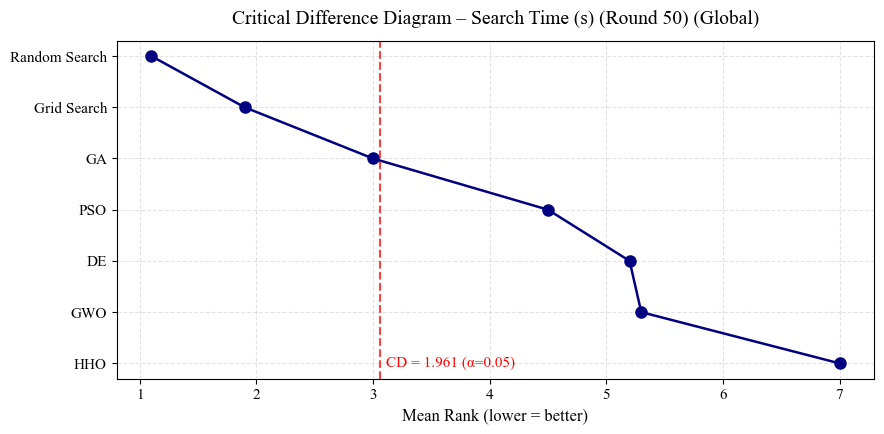

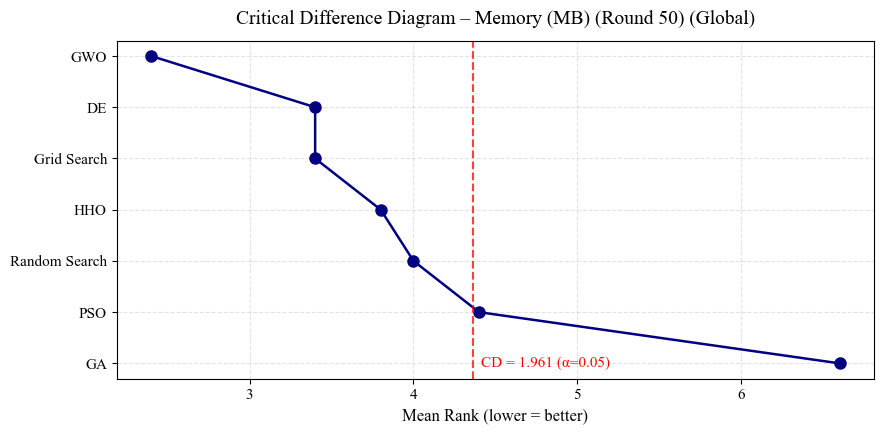


=== Distribution of Optimal Proximal Parameter μ per Method ===

(All 500 values: 10 folds × 50 rounds)


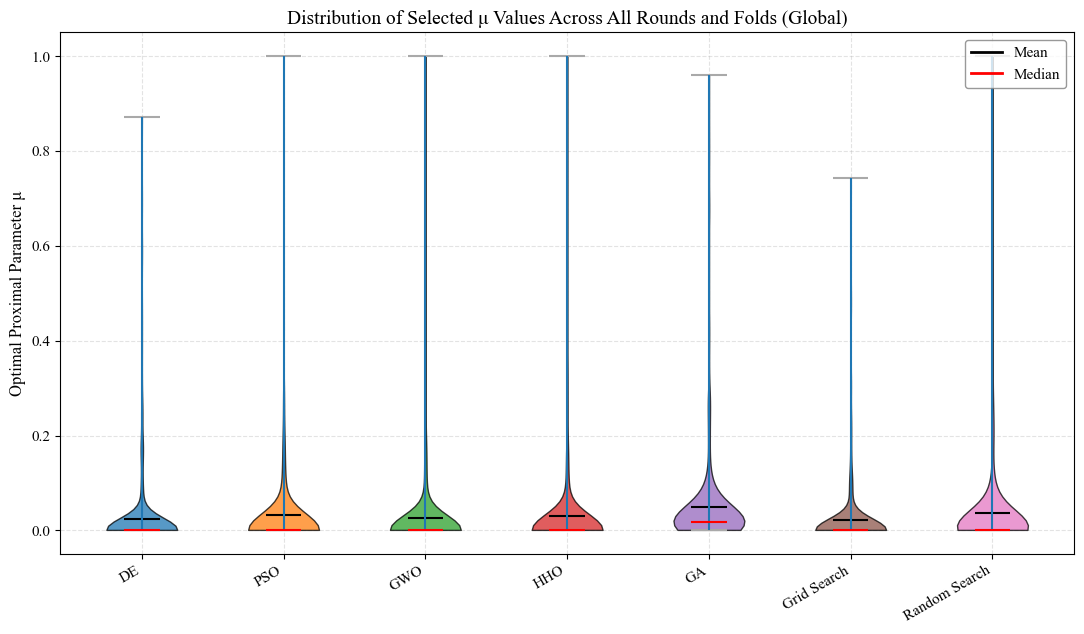


μ Distribution Summary Statistics:
             DE       PSO       GWO       HHO        GA  Grid Search  \
count  500.0000  500.0000  500.0000  500.0000  500.0000     500.0000   
mean     0.0242    0.0321    0.0264    0.0295    0.0488       0.0223   
std      0.0834    0.1203    0.1045    0.1130    0.1087       0.0830   
min      0.0010    0.0010    0.0010    0.0010    0.0010       0.0010   
25%      0.0010    0.0010    0.0010    0.0010    0.0077       0.0010   
50%      0.0010    0.0010    0.0010    0.0010    0.0178       0.0010   
75%      0.0010    0.0010    0.0010    0.0010    0.0415       0.0010   
max      0.8710    1.0000    1.0000    1.0000    0.9597       0.7438   

       Random Search  
count       500.0000  
mean          0.0376  
std           0.1145  
min           0.0010  
25%           0.0010  
50%           0.0010  
75%           0.0266  
max           1.0000  


In [7]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare, wilcoxon
import scikit_posthocs as sp
from matplotlib import rcParams
from itertools import combinations

# =============================================================================
# Academic journal-quality plot settings
# =============================================================================
rcParams['figure.figsize'] = (10, 6)
rcParams['font.family'] = 'serif'
rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']
rcParams['font.size'] = 12
rcParams['axes.titlesize'] = 14
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 11
rcParams['ytick.labelsize'] = 11
rcParams['legend.fontsize'] = 11
rcParams['legend.frameon'] = True
rcParams['legend.edgecolor'] = 'gray'
rcParams['legend.facecolor'] = 'white'
rcParams['legend.loc'] = 'best'
rcParams['grid.alpha'] = 0.35
rcParams['grid.linestyle'] = '--'
rcParams['axes.grid'] = True
rcParams['axes.axisbelow'] = True
rcParams['savefig.dpi'] = 300
rcParams['figure.autolayout'] = True

# Professional color palette
method_colors = {
    'DE': '#1f77b4',
    'PSO': '#ff7f0e',
    'GWO': '#2ca02c',
    'HHO': '#d62728',
    'GA': '#9467bd',
    'Grid Search': '#8c564b',
    'Random Search': '#e377c2'
}

# Load and restructure data
with open('fedprox_results.json', 'r') as f:
    raw_results = json.load(f)

results = {}
for key, value in raw_results.items():
    if key.startswith('fold_'):
        fold_id = key
        for method, metrics in value.items():
            if method not in results:
                results[method] = {}
            results[method][fold_id] = metrics

methods = list(results.keys())

# Collect μ values (all 500 values per method)
mu_data = {m: [] for m in methods}
for m in methods:
    for fold_key in [k for k in results[m] if k.startswith('fold_')]:
        mu_data[m].extend(results[m][fold_key].get('global_mu', []))

df_mu = pd.DataFrame({m: pd.Series(mu_data[m]) for m in methods})

# Metrics to compare (final performance at round 50)
metrics = ['rmse', 'mae', 'r2', 'search_time', 'total_memory']
metric_labels = ['RMSE', 'MAE', 'R²', 'Search Time (s)', 'Memory (MB)']
direction = ['lower', 'lower', 'higher', 'lower', 'lower']  # for interpretation

# Collect final values (round 50) per metric per method per fold
final_data = {met: {m: [] for m in methods} for met in metrics}

for met in metrics:
    for m in methods:
        for fold_key in [k for k in results[m] if k.startswith('fold_')]:
            try:
                final_data[met][m].append(results[m][fold_key][f'global_{met}'][-1])
            except (KeyError, IndexError):
                pass

# Convert to DataFrame for easier analysis
dfs = {}
for met in metrics:
    min_len = min(len(final_data[met][m]) for m in methods)
    data_matrix = np.array([final_data[met][m][:min_len] for m in methods]).T
    dfs[met] = pd.DataFrame(data_matrix, columns=methods)

# =============================================================================
# Statistical tests: Friedman + Nemenyi (or Wilcoxon pairwise fallback)
# =============================================================================
print("=== Statistical Comparison of Global Methods at Round 50 (10 folds) ===\n")

for met, label, dir in zip(metrics, metric_labels, direction):
    print(f"\n--- {label} ({dir} is better) ---")
    
    df = dfs[met]
    
    # Friedman test
    try:
        stat, p = friedmanchisquare(*[df[m] for m in methods])
        print(f"Friedman chi-square = {stat:.4f} | p-value = {p:.6f}")
    except:
        stat, p = np.nan, np.nan
        print("Friedman test failed (possibly due to insufficient data)")
    
    if p < 0.05 and not np.isnan(p):
        # Nemenyi post-hoc
        nemenyi = sp.posthoc_nemenyi_friedman(df)
        print("\nNemenyi pairwise p-values:")
        print(nemenyi.round(4))
    else:
        print("\nNo significant differences (Friedman p ≥ 0.05) → performing pairwise Wilcoxon signed-rank tests")
        print("Pairwise Wilcoxon signed-rank test p-values (no correction):")
        print("-" * 60)
        for m1, m2 in combinations(methods, 2):
            try:
                stat, p = wilcoxon(df[m1], df[m2], alternative='two-sided')
                print(f"{m1} vs {m2}: p = {p:.6f}")
            except:
                print(f"{m1} vs {m2}: test failed (insufficient paired data)")
        print("-" * 60)

# =============================================================================
# Critical Difference Diagram (only if Friedman significant)
# =============================================================================
print("\n=== Critical Difference Diagrams (only if Friedman p < 0.05) ===\n")

for met, label, dir in zip(metrics, metric_labels, direction):
    df = dfs[met]
    try:
        stat, p = friedmanchisquare(*[df[m] for m in methods])
        if p < 0.05:
            k = len(methods)
            n = df.shape[0]
            q_crit = 2.344  # approx for k≈7, alpha=0.05 (Nemenyi table)
            cd = q_crit * np.sqrt(k * (k - 1) / (6.0 * n))

            ranks = df.rank(axis=1, ascending=(dir == 'lower')).mean(axis=0)
            sorted_idx = ranks.argsort()
            sorted_methods = [methods[i] for i in sorted_idx]
            sorted_ranks = ranks.values[sorted_idx]

            fig, ax = plt.subplots(figsize=(9, 4.5))
            ax.plot(sorted_ranks, np.arange(len(methods)), 'o-', color='navy', lw=1.8, ms=8)
            ax.set_yticks(np.arange(len(methods)))
            ax.set_yticklabels(sorted_methods)
            ax.invert_yaxis()
            ax.set_xlabel('Mean Rank (lower = better)' if dir == 'lower' else 'Mean Rank (higher = better)')
            ax.set_title(f'Critical Difference Diagram – {label} (Round 50) (Global)', pad=12)

            best_rank = sorted_ranks[0]
            ax.axvline(x=best_rank + cd, color='red', ls='--', lw=1.5, alpha=0.75)
            ax.text(best_rank + cd + 0.05, len(methods)-1.0, f'CD = {cd:.3f} (α=0.05)', color='red',
                    va='center', ha='left', fontsize=11)

            ax.grid(True, axis='x', alpha=0.35)
            plt.tight_layout()
            plt.show()
        else:
            print(f"Skipped CD for {label} (Friedman p = {p:.6f} ≥ 0.05)")
    except:
        print(f"Could not compute CD for {label} (insufficient data or error)")

# =============================================================================
# 2. Violin plot of optimal μ distribution per method
# =============================================================================
print("\n=== Distribution of Optimal Proximal Parameter μ per Method ===\n")
print("(All 500 values: 10 folds × 50 rounds)")

fig, ax = plt.subplots(figsize=(11, 6.5))

data_list = [df_mu[m].dropna() for m in methods]

vp = ax.violinplot(data_list, showmeans=True, showmedians=True, showextrema=True)

ax.set_xticks(np.arange(1, len(methods) + 1))
ax.set_xticklabels(methods, rotation=30, ha='right')
ax.set_ylabel('Optimal Proximal Parameter μ')
ax.set_title('Distribution of Selected μ Values Across All Rounds and Folds (Global)')

# Customize violin colors
for i, pc in enumerate(vp['bodies']):
    pc.set_facecolor(method_colors.get(methods[i], 'gray'))
    pc.set_edgecolor('black')
    pc.set_alpha(0.75)

vp['cmeans'].set_color('black')
vp['cmedians'].set_color('red')
vp['cmaxes'].set_color('darkgray')
vp['cmins'].set_color('darkgray')

# Legend for mean & median
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='black', lw=2, label='Mean'),
    Line2D([0], [0], color='red',   lw=2, label='Median')
]
ax.legend(handles=legend_elements, loc='upper right', frameon=True, edgecolor='gray')

ax.grid(True, axis='y', alpha=0.35)
plt.tight_layout()
plt.show()

# Summary statistics of μ
print("\nμ Distribution Summary Statistics:")
print(df_mu.describe().round(4))